# Activity7.06: Education, annual salary, and weekly working hours

LU MENGJIE — MC643920  
Suggested Exercise 07 · Practice 02

Data: `age_salary_hours.csv`. The education treemap uses all 500 records; both outcome plots use only records with Age < 65.

## Activity7.06 — 01. Read all 500 people and set the education order

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from IPython.display import display

DATA_DIR = Path('../../Datasets')
pd.set_option('display.max_columns', 8)
pd.set_option('display.width', 110)
print('LU MENGJIE | MC643920 | Python 3 / Seaborn', sns.__version__)
import squarify
sns.set_theme()
data = pd.read_csv(DATA_DIR / 'age_salary_hours.csv')
ordered_degrees = ['No diploma', 'High school diploma', 'Attended college, no degree',
                   "Associate's degree", "Bachelor's degree or higher"]
colors = dict(zip(ordered_degrees, sns.color_palette('colorblind', 5)))
print('Input records:', len(data))
display(data.head())

LU MENGJIE | MC643920 | Python 3 / Seaborn 0.13.2
Input records: 500


,Age,Annual Salary,Weekly hours,Education
0,72,160000.0,40.0,Bachelor's degree or higher
1,72,100000.0,50.0,Bachelor's degree or higher
2,31,120000.0,40.0,Bachelor's degree or higher
3,28,45000.0,40.0,Bachelor's degree or higher
4,54,85000.0,40.0,Bachelor's degree or higher


## Activity7.06 — 02. Calculate education shares for the full sample

In [2]:
counts = data['Education'].value_counts().reindex(ordered_degrees)
percentages = counts / counts.sum() * 100
labels = [degree + f'\n({percentage:.1f}%)'
          for degree, percentage in percentages.items()]
print('Total people:', counts.sum(), '| Total percentage:', percentages.sum())
display(pd.DataFrame({'People': counts, 'Percentage': percentages}))

Total people: 500 | Total percentage: 100.0


,People,Percentage
Education,,
No diploma,17,3.4
High school diploma,107,21.4
"Attended college, no degree",89,17.8
Associate's degree,50,10.0
Bachelor's degree or higher,237,47.4


## Activity7.06 — 03. Draw the education treemap

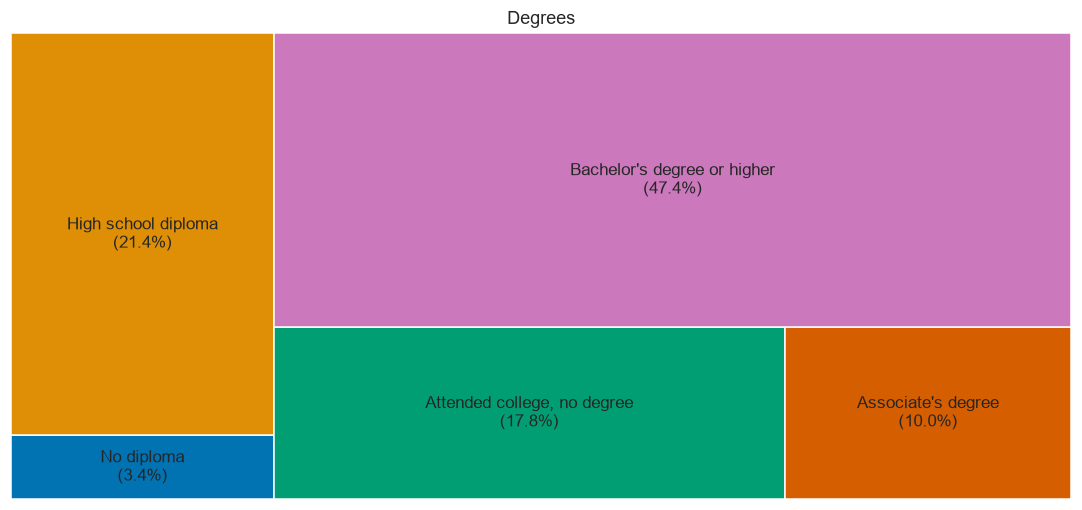

In [3]:
plt.figure(figsize=(10, 4.8), dpi=110)
squarify.plot(sizes=percentages, label=labels,
              color=[colors[d] for d in ordered_degrees],
              text_kwargs={'fontsize': 11},
              bar_kwargs={'edgecolor': 'white', 'linewidth': 1})
plt.title('Degrees')
plt.axis('off')
plt.tight_layout()
plt.show()

## Activity7.06 — 04. Exclude people aged 65 or over and summarize both outcomes

In [4]:
working_age = data[data['Age'] < 65].copy()
print('People younger than 65:', len(working_age))
print('Maximum included age:', working_age['Age'].max())
summary = working_age.groupby('Education').agg(
    People=('Age', 'size'), Median_salary=('Annual Salary', 'median'),
    Median_weekly_hours=('Weekly hours', 'median')).reindex(ordered_degrees)
display(summary)

People younger than 65: 385
Maximum included age: 64


,People,Median_salary,Median_weekly_hours
Education,,,
No diploma,11,38000.0,40.0
High school diploma,74,29000.0,37.0
"Attended college, no degree",70,20400.0,39.0
Associate's degree,35,34000.0,38.0
Bachelor's degree or higher,195,61000.0,40.0


## Activity7.06 — 05. Create both violin plots in a two-row subplot

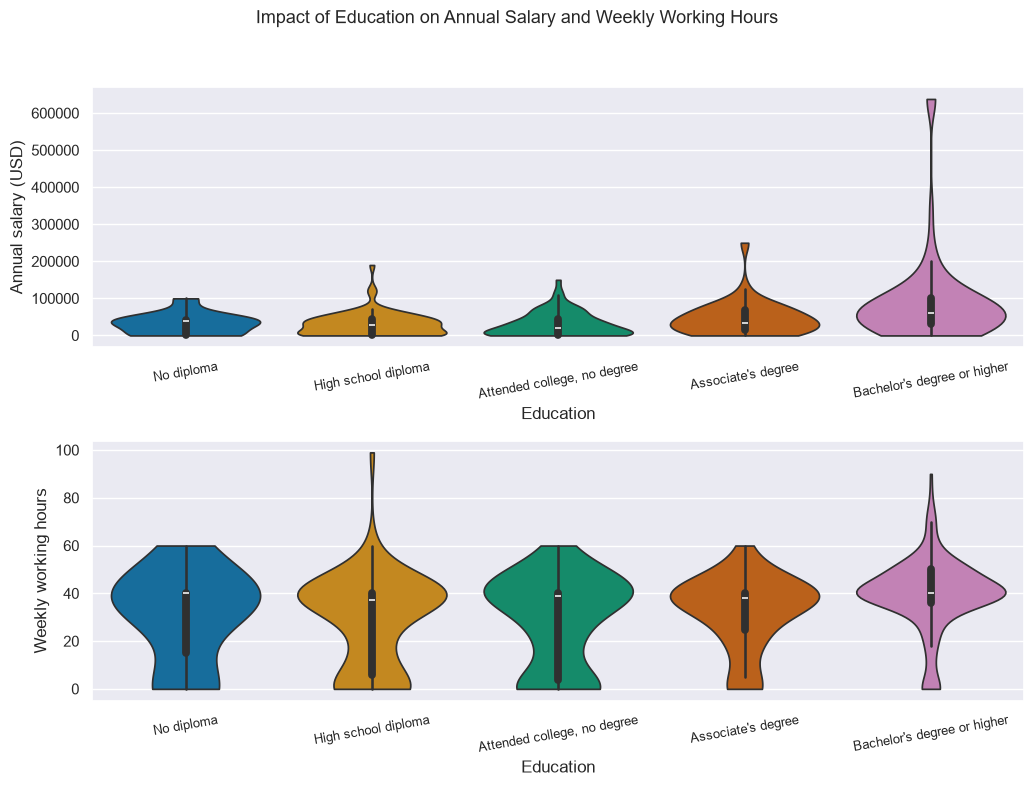

In [5]:
fig, ax = plt.subplots(2, 1, figsize=(10.5, 8), dpi=100)
for axis, outcome in zip(ax, ['Annual Salary', 'Weekly hours']):
    sns.violinplot(data=working_age, x='Education', y=outcome,
                   hue='Education', order=ordered_degrees, hue_order=ordered_degrees,
                   palette=colors, legend=False, cut=0, ax=axis)
    axis.tick_params(axis='x', labelrotation=10, labelsize=9)
    axis.set_xlabel('Education')
ax[0].set_ylabel('Annual salary (USD)')
ax[1].set_ylabel('Weekly working hours')
fig.suptitle('Impact of Education on Annual Salary and Weekly Working Hours', fontsize=13)
fig.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

The bachelor's-degree-or-higher group has the highest sample median salary and the largest upper salary tail. Median weekly hours are similar across education groups, with overlapping distributions. These sample associations cannot isolate a causal education effect or represent the whole state without a sampling and weighting analysis.